# Quantum Metal tutorial 2.22 — 100 qubits on a staggered grid, generated programmatically (Quantcore PDK rebuild)

**What the chip is.** The Qiskit Metal tutorial
`docs/tut/2-From-components-to-chip/2.22-Design-100-qubits-programmatically.ipynb`, © Qiskit Metal contributors,
Apache-2.0 (<https://github.com/qiskit-community/qiskit-metal>); spec `docs/designs/metal/tut222_100q_grid.md`. We
distribute the rebuild under GPL-3.0. A 10 × 10 grid of `TransmonPocket` qubits (Metal defaults, four connection
pads B0–B3, orientation −90°) on a brick lattice: 3 mm pitch, odd columns shifted up by 1.5 mm. Meandered buses join
each qubit to the one above (`CU_x_y`, B0 → B3, 7.0 / 7.5 mm alternating by row, 90 of them) and to the up-right
neighbour (`CS_x_y`, B1 → B2, 6.0 / 6.5 mm, 86), so no qubit sees two equal buses. No launchpads, readouts or
control lines — the tutorial: "not a practical design given the lack of readouts or control lines to the qubits,
just an example for how to make a design algorithmically".

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
Metal components are drawn through the `metal:<Class>` wrapper with the tutorial's own options and the buses follow
Metal's own meanders; the chip, the stack, the junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal tutorial 2.22 | Quantcore PDK rebuild |
|---|---|---|
| chip | (N + 1)·3 = 33 mm square, centred at (13.5, 14.25) mm | the same 33 × 33 mm box with the QCT die frame (Designer = Metal + (3000, 2250) µm) |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| pads | none | none (nothing for the pad rule to move) |
| junctions | `FakeJunction_01` GDS cell; its LOM uses 12.31 nH + 2 fF (a value, not a target) | Quantcore Nb/AlOx/Nb trilayer junction, PDK nominal 0.5 × 0.6 µm (R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF), all 100 identical |
| cheese | **Metal's GDS cheese** (the tutorial exports `NxN_Chip.gds` with `no_cheese.buffer = 50um`: 25 µm holes every 100 µm over the ground) | the original's Metal rule, drawn by the build (chip `cheese` = `metal_cheese_rule(buffer=50)`) |
| buses | `RouteMeander` (fillet 99 µm, asymmetry −700 / −200 µm) | qcc fixed-length routes on Metal's own meander corner points (computed by running the tutorial's loops in a headless Metal design) |
| placement | the grid sits 0.34 mm right of the chip centre | content centred in the die (shift printed in Design 8) |

**Kept exactly:** the tutorial's two generator loops, run twice — once in a headless Metal design (Design 6, about
15 s) to get every `RouteMeander`'s own corner points, and once here with `metal:TransmonPocket` and qcc routes on
those corner points (fillet 99 µm, 10 / 6 µm CPW, Metal's defaults) — so every qubit, pin and bus path is Metal's
(up to the centring shift). The source's typo `loc_w` on B3 is kept (harmless: `loc_W` defaults to +1).

**Not reproduced:** the tutorial's Q3D + LOM run (Ansys; it fails in the stored notebook without Windows) and its
fake junction GDS cells. The LOM here is qcc's (LOM 1) and the Q3D jobs are exported (Simulate 1).

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own cell with a
picture of the chip so far — the die, the 100 qubits, the 176 buses on Metal's own meanders, and then the whole chip
(no pads, readouts or control lines: those segments say so in one sentence). The chip is large (100 qubits, 176
buses, 33 mm): each full rebuild takes tens of seconds, so only the qubit, bus and whole-chip segments take a
picture of the build. Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in one cell, with its outputs) is kept as `tut222_100q_grid.v1.ipynb`; both save the same
`tut222_100q_grid.json`.

## Setup

The imports, the output folder, the grid size, the Metal → Designer helper `P`, the tutorial's pad options `PADS` and the switches. `LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it;
with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement, FEM and feedback helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
import logging, warnings
N_x = N_y = 10
X0, Y0 = 3000, 2250                              # Metal's chip spans x −3…30 mm, y −2.25…30.75 mm
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm
PADS = dict(B0=dict(loc_W=-1, loc_H=-1, pad_width="75um"), B1=dict(loc_W=-1, loc_H=+1, pad_width="120um"),
            B2=dict(loc_W=+1, loc_H=-1, pad_width="120um"), B3=dict(loc_w=+1, loc_H=+1, pad_width="90um"))

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 33 mm box gets the QCT frame; there are no pads for the pad rule; the 100 qubits get the PDK nominal trilayer junction; the cheese is the original's (Metal's GDS cheese), drawn by the build instead of the PDK band.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). The tutorial's own words: "not a practical design given the lack of readouts or control lines to the
qubits, just an example for how to make a design algorithmically"; so only segments 4 and 6 place anything.

| segment | what is placed here |
|---|---|
| 1 | the 33 × 33 mm die with the QCT frame and the original's Metal cheese rule |
| 2–3 | nothing: no bond pads and no feedline (the tutorial: an algorithmic example) |
| 4 | the 100 qubits on the brick lattice (the tutorial's first loop) |
| 5 | nothing: no readout resonators |
| 6 | the coupling: the 176 buses on Metal's own meander corner points (the second loop) |
| 7 | nothing: no control lines |
| 8 | the whole chip: sim groups, centring, the full build, save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm); the PDK draws the **QCT frame** on it: L
dicing markers in the four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary
(100/0) and the device ID `name_chip` on a free edge (optional: no free edge, no ID). Metal's 33 mm chip spans
x −3…30 mm, y −2.25…30.75 mm, so `P(x, y)` = Metal + (3000, 2250).

**Cheese: the original's.** The source exports its GDS with Metal's cheese on (Fab 1), so the original's cheese wins over the PDK band: `chip={"cheese": metal_cheese_rule(buffer=50)}` hands the build Metal's rule (25 µm squares every 100 µm, 50 µm clear of every etched shape, none within 200 µm of the die edge), and the build draws it instead of the band (`_common.metal_cheese_rule`).

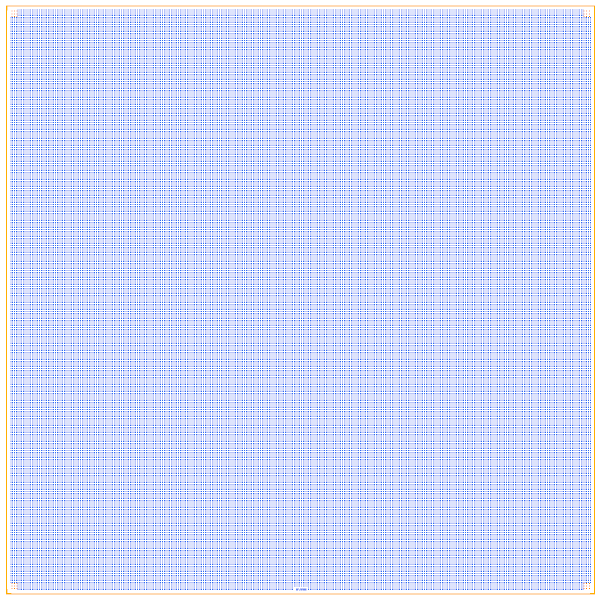

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/tut222_100q_grid_s1_die.png')

In [5]:
d = Designer("tut222_100q_grid", box=(0, 0, 33000, 33000), chip={"name_chip": "MetalTut222", "cheese": metal_cheese_rule(buffer=50)},
             live=LIVE)
layout_step(d, OUT / "tut222_100q_grid_s1_die.png", size=(600, 600), width=300)

## Design 2 · Bond pads

Tutorial 2.22 has no launchpads, so the PDK pad rule (outer etch edge 100 µm from the die edge) has nothing to place;
`pads_md(d)` in Design 8 confirms there are none.

## Design 3 · Readout: the line

No feedline or readout pads either.

## Design 4 · Qubit placement: 100 TransmonPockets

**The qubits.** The tutorial's first loop: `metal:TransmonPocket` with Metal's defaults (pads 455 µm, pocket
650 µm), orientation −90°, at (3x, 3y + 1.5·(x mod 2)) mm, with four connection pads B0–B3 of widths 75 / 120 / 120 /
90 µm (so no qubit sees two equal buses).

**The junction.** With `junction_type` unset the wrapper already draws the Quantcore trilayer junction;
`trilayer_junction` makes it explicit and returns the drawn junction's L_J and C_J for the LOM and the FEM junction
port (`junction=`). The tutorial's LOM value (12.31 nH) is not a frequency target, so every qubit gets the PDK
nominal junction (fingers 0.5 × 0.6 µm on 2/0 + 4/0, a 50/0 spacer with the 51–53/0 dose gradient, R_n 45 kΩ,
L_J 6.73 nH, C_J 15 fF).

The picture zooms on the bottom-left corner of the grid (Q_0_0, Q_0_1, Q_1_0, Q_1_1).

junction: {'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


100 qubits; Q_0_0 ports: ['B0', 'B1', 'B2', 'B3', 'squid_a', 'squid_b']


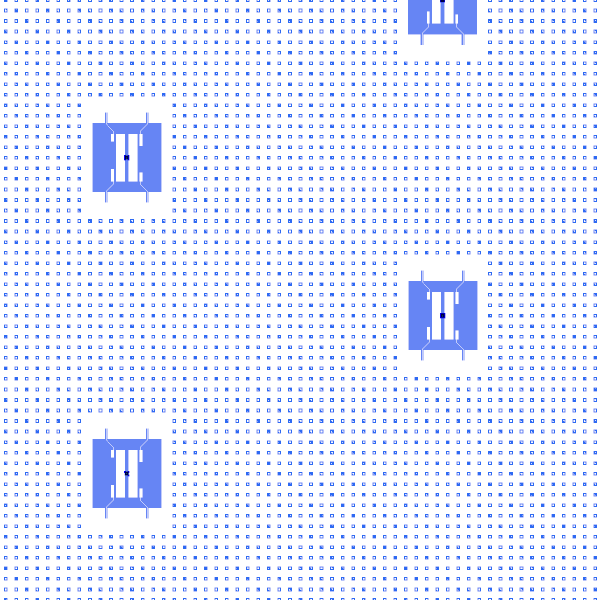

**On the chip so far:** 0 pads · 100 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 100 component(s) `Q_0_0`, `Q_0_1`, `Q_0_2`, `Q_0_3`, `Q_0_4`, `Q_0_5`, `Q_0_6`, `Q_0_7` … (+92).

WindowsPath('examples/designs/metal/tut222_100q_grid_step_parts.png')

In [6]:
# Quantcore trilayer junction on the PDK rule (Nb Δ 1.4 meV): nominal fingers 0.5 × 0.6 µm → R_n 45 kΩ,
# L_J 6.73 nH, C_J 15 fF. JJ_PARAMS = {"junction_type": "Quantcore Junction"}; JUNCTION = its {Lj_nH, Cj_fF}
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonPocket")
print("junction:", JJ_PARAMS, JUNCTION)
with d.batch():
    q = {f"Q_{x}_{y}": d.add(f"Q_{x}_{y}", "metal:TransmonPocket", at=P(x * 3000, y * 3000 + (x % 2) * 1500),
                             rot=-90, junction=JUNCTION, **JJ_PARAMS, connection_pads=PADS)
         for x in range(N_x) for y in range(N_y)}
print(len(q), "qubits; Q_0_0 ports:", sorted(q["Q_0_0"].ports))
layout_step(d, OUT / "tut222_100q_grid_step_parts.png", box=P(-1200, -1200) + P(4500, 4500), size=(600, 600),
            width=300)

## Design 5 · Readout: the resonators

None: no qubit has a readout resonator; the free pads on the grid edges stay open (Check 1 counts them).

## Design 6 · Coupling: Metal's own meanders

**Metal's corner points.** The tutorial's second loop creates a `RouteMeander` per bus (`cu`: the "upward" bus B0 →
B3, 7.0 / 7.5 mm, lead 0.5 / 0.25 mm, asymmetry −700 µm; `cs`: the "sideways" bus B1 → B2, 6.0 / 6.5 mm, lead
0.3 / 0.25 mm, asymmetry −200 µm). Running both loops in a headless Metal design gives every meander's own corner
points (`get_points()`), so the rebuild can lay its routes exactly on Metal's paths.

In [7]:
def cu(x, y):  # the tutorial's "upward" bus (or None)
    return dict(total_length=f"{7 + (y % 2) * 0.5}mm", lead=dict(start_straight="0.5mm", end_straight="0.25mm"),
                meander=dict(asymmetry="-700um"), ends=((f"Q_{x}_{y}", "B0"), (f"Q_{x}_{y + 1}", "B3"))) \
        if y < N_y - 1 else None

def cs(x, y):  # the tutorial's "sideways" bus (or None)
    return dict(total_length=f"{6 + (y % 2) * 0.5}mm", lead=dict(start_straight="0.3mm", end_straight="0.25mm"),
                meander=dict(asymmetry="-200um"), ends=((f"Q_{x}_{y}", "B1"), (f"Q_{x + 1}_{y + x % 2}", "B2"))) \
        if x < N_x - 1 and not (x % 2 and y == N_y - 1) else None

# the tutorial's loops in a headless Metal design: every RouteMeander's corner points (µm, Metal frame)
os.environ["QISKIT_METAL_HEADLESS"] = "True"
logging.disable(logging.WARNING); warnings.simplefilter("ignore")
from qiskit_metal import designs
from qiskit_metal.qlibrary.qubits.transmon_pocket import TransmonPocket
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
mdesign = designs.DesignPlanar()
for x in range(N_x):
    for y in range(N_y):
        TransmonPocket(mdesign, f"Q_{x}_{y}", dict(pos_x=f"{x * 3000}um", pos_y=f"{y * 3000 + (x % 2) * 1500}um",
                                                   orientation="-90", connection_pads=PADS))
PATHS, BUSES = {}, {}
for x in range(N_x):
    for y in range(N_y):
        for name, opt in ((f"CU_{x}_{y}", cu(x, y)), (f"CS_{x}_{y}", cs(x, y))):
            if opt is None:
                continue
            (q0, p0), (q1, p1) = opt.pop("ends")
            r = RouteMeander(mdesign, name, options=dict(fillet="99um", **opt, pin_inputs=dict(
                start_pin=dict(component=q0, pin=p0), end_pin=dict(component=q1, pin=p1))))
            PATHS[name] = [(1000 * float(a), 1000 * float(b)) for a, b in r.get_points()]
            BUSES[name] = (q0, p0, q1, p1, 1000 * float(opt["total_length"][:-2]))
logging.disable(logging.NOTSET)
print(len(PATHS), "Metal buses;", sum(len(v) for v in PATHS.values()), "corner points")

176 Metal buses; 3676 corner points


**The qcc routes.** Each bus becomes a fixed-length route (`meander=length`) between the same two pins, with
Metal's interior corner points as waypoints (fillet 99 µm as the turn radius, 10 / 6 µm CPW). The waypoint path is Metal's
length, and the 0.05 µm over Metal's `total_length` keeps the target at or above it: the router draws no `Meander` for so small a leftover, it puts it into the free corners (their bend radius a few nm smaller), so every bus stays on Metal's path. In the LOM each bus is a λ/2 `TLres` open
at both pads.

The picture is the first full build (100 qubits, 176 buses: tens of seconds), zoomed on the grid's bottom-left
corner.

176 routes


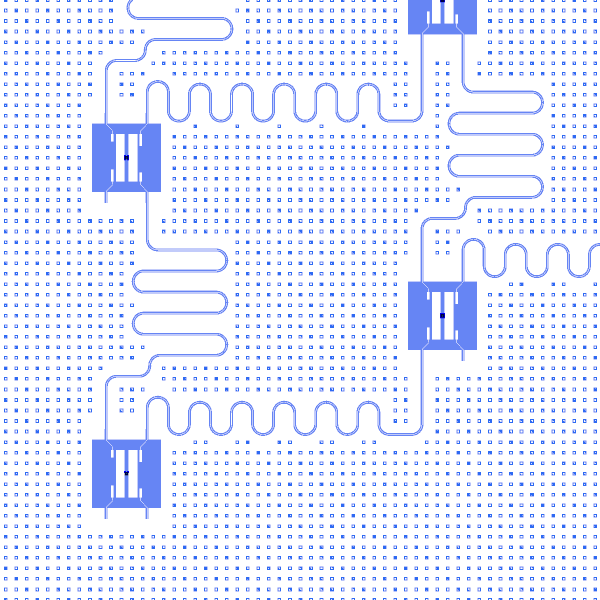

**On the chip so far:** 0 pads · 100 qubits · 0 other components · 176 routes · 0 declared couplings. **This step added** 176 route(s) `CU_0_0`, `CS_0_0`, `CU_0_1`, `CS_0_1`, `CU_0_2`, `CS_0_2`, `CU_0_3`, `CS_0_3` … (+168).

WindowsPath('examples/designs/metal/tut222_100q_grid_s6_buses.png')

In [8]:
with d.batch():
    # fixed-length meanders (λ/2 buses in the LOM) on Metal's corner points; the 0.05 µm over Metal's total_length
    # keeps the router on Metal's path
    for name, (q0, p0, q1, p1, length) in BUSES.items():
        d.route(name, getattr(q[q0], p0), getattr(q[q1], p1), meander=length + 0.05, r=99, a=10, b=6,
                nodes=[P(x, y) for x, y in PATHS[name][1:-1]])
print(len(d.data["routes"]), "routes")
layout_step(d, OUT / "tut222_100q_grid_s6_buses.png", box=P(-1200, -1200) + P(4500, 4500), size=(600, 600), width=300)

## Design 7 · Routing: control lines

None: the tutorial draws no charge or flux lines.

## Design 8 · The whole chip: sim groups, centring, save

**Sim groups:** Q_0_0 alone (the tutorial's Q3D case: the box cuts its four buses, as its open terminations do) and
the Q_0_0–Q_0_1 pair with their bus, both Q3D C-matrix jobs with a 300 µm margin.

**Centring.** The PDK wants the chip content centred in the die. Metal's grid sits off its own chip's centre (the qubit pockets
and meanders reach further to the right than to the left), so `center_in_die` — which measures the bounding box of
everything placed and shifts every qubit position and route waypoint — moves the whole grid left by about 0.34 mm. Then the chip is built again (100 qubits, 176 buses) and the bus lengths are listed per
family.

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's): the segments above changed how the chip is built, not the chip, so it should say *same design*.

['Q00_CU00_Q01', 'Q_0_0']


content shifted by (-336.7, 0.0) µm
CU 90 buses, lengths (µm): [7000.0, 7500.0]
CS 86 buses, lengths (µm): [6000.1, 6500.1]


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

**Same design as before:** `examples/designs/metal/tut222_100q_grid.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer tut222_100q_grid: 100 instances, 176 routes, live=False> → examples\designs\metal\tut222_100q_grid.json


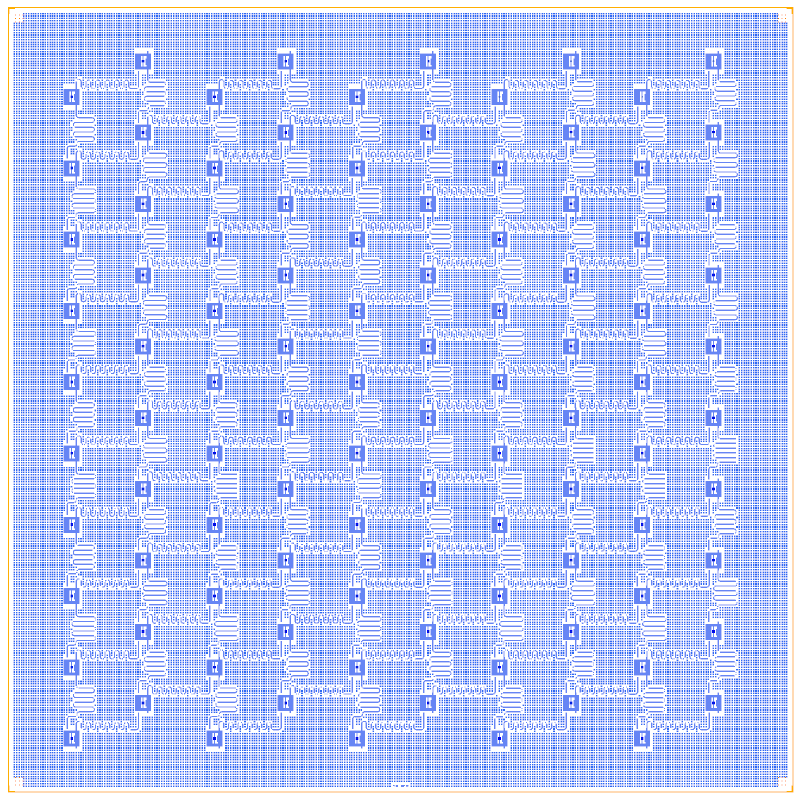

**On the chip so far:** 0 pads · 100 qubits · 0 other components · 176 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/tut222_100q_grid_step_routes.png')

In [9]:
# FEM: Q_0_0 alone (the tutorial's Q3D), and the Q_0_0–Q_0_1 pair with their bus
d.sim_group("Q_0_0", ["Q_0_0"], margin_um=300, analyses=["q3d_cmatrix"])
d.sim_group("Q00_CU00_Q01", ["Q_0_0", "CU_0_0", "Q_0_1"], margin_um=300, analyses=["q3d_cmatrix"])
print(sorted(d.data["sim_groups"]))
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
L = d.result.route_lengths()
for fam in ("CU", "CS"):
    vals = sorted({round(v, 1) for k, v in L.items() if k.startswith(fam)})
    print(fam, sum(k.startswith(fam) for k in L), "buses, lengths (µm):", vals)
display(Markdown(pads_md(d)))
DESIGN, same = save_design(d, OUT / "tut222_100q_grid.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, OUT / "tut222_100q_grid_step_routes.png", size=(800, 800), width=400)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here (from the v1 run): **no errors**, no overlaps, and 248 `dangling_port` warnings: the 200 junction attachment
points (`squid_a` / `squid_b`, drawn by the cell) and the 48 pads the generator leaves free on the grid edges (B0 on
the top row, B3 on the bottom row, B2 on the left column and the four even-column bottom qubits, B1 on the right
column and the four odd-column top qubits: Metal draws them as short open leads, and so does the rebuild); **no PDK
design warnings** (no pads, the nominal junction is in the R_n window, no targets).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [ ]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: each `TransmonPocket` gives two floating pads (`island1` /
`island2`) with the junction, and a coupler node per connection pad; every bus between two pads is a λ/2 `TLres`
(open at both pads). Whole chip: 100 qubits and 176 buses. The table lists the first nodes and branches only (the
full netlist is in `lb`), then Q_0_0's port map.

In [ ]:
from collections import Counter
lb = d.lom()
md_ = netlist_md(lb)
print(md_.splitlines()[0])
display(Markdown("\n".join(md_.splitlines()[:40]) + "\n\n…"))
print(Counter(b.type for b in lb.model.branches.values()))
print({k: v for k, v in lb.port_map.items() if k.startswith("Q_0_0.")})

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

QuCat cannot solve 100 qubits and 176 buses at once, so: Q_0_0 alone (the tutorial's LOM case, all four pads open:
its four buses are outside the selection), then the corner qubit with its two neighbours and their buses
(Q_0_0 –CU_0_0– Q_0_1, Q_0_0 –CS_0_0– Q_1_0) for the bus frequencies and the static ZZ. QuCat gives the linear
normal modes; the tables under them have the QuTiP dressed values (f_q includes the anharmonic shift).

With the PDK junction (6.73 nH, 15 fF; numbers from the v1 run) Q_0_0 sits near 6.9 GHz, below the 8.4–9.5 GHz λ/2 buses (the tutorial's
Metal LOM *assumes* 6.0 / 6.2 / 6.4 GHz buses; the drawn 6–7.5 mm λ/2 buses are higher). Two neighbours whose bus pads
have equal widths (B1 / B2, both 120 µm) can hybridise through their bus (ZZ "hybridised", not defined). All 100
qubits share one junction, so the grid has no frequency plan beyond the bus lengths.

In [ ]:
single = simulate_groups(d, {"Q_0_0": ["Q_0_0"]})
display(Markdown("**Q_0_0 (pads open), QuCat normal mode:**\n\n" + modes_md(single["Q_0_0"]) + "\n\n" + groups_md(single)))
pairs = simulate_groups(d, {"Q_0_0+CU_0_0+Q_0_1": ["Q_0_0", "CU_0_0", "Q_0_1"],
                            "Q_0_0+CS_0_0+Q_1_0": ["Q_0_0", "CS_0_0", "Q_1_0"]}, max_modes=3)
for g, r in pairs.items():
    display(Markdown(f"**{g}, QuCat normal modes:**\n\n" + modes_md(r)))
display(Markdown(groups_md(pairs)))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(pairs)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of Q_0_0 alone and of the two corner pairs (QuCat; circles are
qubits, squares the bus; filled markers are the QuTiP dressed values), (b) the dispersive shift |χ| of each bus. Here
(from the v1 run) the qubits sit near 6.9 GHz, the 7 mm `CU` bus at 8.36 GHz and the 6 mm `CS` bus at 9.51 GHz; in
the `CS_0_0` pair the two qubit modes are mixed (the hybridised pair of the ZZ table).

In [ ]:
plot_lom({**single, **pairs}, OUT / "tut222_100q_grid_lom.png", title="tut222: LOM of the corner")

## LOM 3 · One geometry change, by hand

Before the FEM, a hand-made design step: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property — here Q_0_0's main pads, `pad_width` 455 µm (Metal's default) → 400 µm — rebuild, re-run
the LOM of Q_0_0 alone and compare. Narrower pads have less capacitance: E_C grows, so f_q and |α| go up. (The copy
holds the whole chip, so its LOM build takes a few seconds even for one qubit.)

In [ ]:
d2 = design_copy(DESIGN)
d2["Q_0_0"].set(pad_width=400)                   # Metal default 455 → 400 µm
after = simulate_groups(d2, {"Q_0_0": ["Q_0_0"]})
display(Markdown(params_delta_md(single, after)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/metal/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

Q3D C-matrix jobs for the two sim groups: `Q_0_0` (the tutorial's Q3D of one qubit; the box cuts its four
buses, as its open terminations do) and `Q00_CU00_Q01` (Q_0_0 with Q_0_1 and the 7 mm bus between them: the pad-to-bus
capacitances that set the coupling).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

Neither group lists an eigenmode analysis, but `export_sims` exports any analysis of an existing group, so the
eigenmode job of `Q_0_0` (Simulate 3) comes from the same design: nothing is added to it.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/metal/fem/: solved results are kept here
jobs = export_sims(DESIGN, ["Q_0_0", "Q00_CU00_Q01"])
jobs_eig = export_sims(DESIGN, ["Q_0_0"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrices

The capacitance of each component group: `Q_0_0` (one qubit, its four buses cut by the box: C_Σ and the pad
capacitances) and `Q00_CU00_Q01` (Q_0_0 with Q_0_1 and the 7 mm bus between them: the pad-to-bus capacitances that
set the coupling). Each net is named after its LOM node, so the matrix goes straight into the circuit (Results 3).
`fem_stage` solves each job with `RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The `Q_0_0` box in HFSS eigenmode: the junction is a lumped L_J ‖ C_J sheet and the buses the box cuts end in 50 Ω
there, so the qubit mode's Q is that loading (not a T1 of the chip, whose buses run on to the next qubits). pyEPR (run
inside qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) turns the junction's energy participation into Q_0_0's
dressed f_q and α, to compare with the LOM.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run

Nothing to drive: the grid has no readout resonator and no port of its own (an S21 between two cut bus ends would
not be a measurement of this chip).

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit), with the LOM's Q_0_0 frequency as a dashed line. The
table below lists the modes and the pyEPR values.

In [ ]:
lom_f = {"Q_0_0": single["Q_0_0"].params.get("Q_0_0.f_q_GHz")}
plot_eigenmodes(keep_eig, OUT / "tut222_100q_grid_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms: Q_0_0's mode is the one its junction participates in most; f_q is pyEPR's
dressed frequency, α its self-Kerr. There is no readout to read (`epr_values` gets a placeholder readout, and only
Q_0_0's values are kept).

In [ ]:
fem_q = {}
if keep_eig["Q_0_0"]:
    fem_q = {k: v for k, v in epr_values(keep_eig["Q_0_0"], {"Q_0_0": "none"}, {"none": 0.0}).items()
             if k.startswith("Q_0_0.")}
if fem_q:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(f"| `{k}` | {v:.5g} |" for k, v in fem_q.items())))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list Q_0_0's f_q and α from pyEPR.")

## Results 3 · FEM against the LOM

**LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates by a job's C-matrix values (matched by net
name) and the same LOM runs again: `Q_0_0` alone with its own job, the `Q_0_0+CU_0_0+Q_0_1` pair with the
`Q00_CU00_Q01` job. **FEM directly:** Q_0_0's eigenmode values (Results 2). The left column is the LOM on the
component estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill

rows = []
for g, sel, job in (("Q_0_0", ["Q_0_0"], "Q_0_0"), ("Q_0_0+CU_0_0+Q_0_1", ["Q_0_0", "CU_0_0", "Q_0_1"], "Q00_CU00_Q01")):
    est = (single | pairs)[g].params
    if keep_q3d.get(job):
        on_fem = simulate(fill(d.lom(select=sel).model, DESIGN, keep_q3d[job]), max_modes=2 if g == "Q_0_0" else 3).params
        rows += [(f"{g}: {k}", v, on_fem.get(k), f"LOM on the {job} Q3D C-matrix") for k, v in est.items()
                 if k.endswith(("f_q_GHz", "alpha_MHz", ".f_GHz"))]
rows += [(k, single["Q_0_0"].params.get(k), fem_q[k], "Q_0_0 eigenmode + pyEPR")
         for k in ("Q_0_0.f_q_GHz", "Q_0_0.alpha_MHz") if k in fem_q]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q and α of the LOM next to the LOM on the Q3D "
          "C-matrices and next to Q_0_0's eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards a target

The tutorial states no targets, and every qubit has the same junction, so neighbours sit within a few MHz of each
other (LOM 1: Q_0_0 and Q_0_1 ≈ 11 MHz apart in the v1 run). This notebook sets one target as an exercise that
detunes a neighbour pair: **Q_0_1 at 6.75 GHz** (dressed), ≈ 0.15 GHz below where the LOM puts it (from the v1 run:
6.90 GHz). It is reachable inside the PDK junction window: by the transmon formula Q_0_1's L_J goes from 6.73 nH to
≈ 7.0 nH, R_n ≈ 47 kΩ.

**Big chip: one sim group's circuit.** The estimators of `loop.analyse` on 100 qubits and 176 buses would take far too
long; the step works on one sim group's selection instead, `Q00_CU00_Q01` (Q_0_0, the bus `CU_0_0`, Q_0_1), as the
LOM 1 pair does. And `loop.feedback` tunes qubit–readout pairs, which this chip does not have (a bus is reached by two
qubits, so the circuit analysis treats it as a bus), so the step is a first-order rule in the notebook: for a
transmon f_q ∝ 1/√L_J, so **L_J ← L_J · (f_now / f_target)²**, kept inside the PDK window (`pdk_lj_bounds`: R_n
40–50 kΩ). The new L_J is drawn (`trilayer_junction(..., lj_nH=...)` sizes the fingers and gives C_J) on a copy of the
design (`design_copy`: the whole chip, so each measurement takes a few seconds). Only L_J moves, so the capacitances
do not: when the `Q00_CU00_Q01` Q3D job is kept (Simulate 2) its C-matrix fills every revision's circuit (the FEM
point), otherwise the LOM estimates do. The table shows one step.

In [ ]:
from quantcore_circuits.circuit.fill import fill

Q_T, F_T, TOL = "Q_0_1", 6.75, 0.020             # the exercise target: Q_0_1 at 6.75 GHz ± 20 MHz (dressed)
G_T = ["Q_0_0", "CU_0_0", "Q_0_1"]                # the sim group Q00_CU00_Q01's selection (and the LOM 1 pair)
LO, HI = pdk_lj_bounds(DESIGN)[f"{Q_T}.junction.Lj_nH"]   # the PDK R_n window as L_J bounds (nH)
FEM0 = keep_q3d.get("Q00_CU00_Q01")               # a kept Q3D job of the group: its C-matrix holds for every revision


def measure(dd):
    """Q_0_1's dressed f_q (GHz) on design dd: the LOM of the group, filled with the kept group job if any."""
    return simulate(fill(dd.lom(select=G_T).model, dd.design, FEM0), max_modes=3).params.get(f"{Q_T}.f_q_GHz")


def lj_step(dd, f_now):
    """The feedback rule on dd: f_q ∝ 1/√L_J to first order, so L_J ← L_J · (f_now / F_T)², inside the PDK window;
    the new junction is drawn. Returns (L_J before, L_J drawn, whether the window clipped it)."""
    lj_now = dd.data["instances"][Q_T]["junction"]["Lj_nH"]
    want = lj_now * (f_now / F_T) ** 2
    jp, jj = trilayer_junction("metal:TransmonPocket", lj_nH=min(max(want, LO), HI))
    dd[Q_T].set(junction=jj, **jp)
    return lj_now, jj["Lj_nH"], not LO <= want <= HI


d_t = design_copy(DESIGN, "_target")             # the revisions are made on this copy; the design file stays
f0 = measure(d_t)
lj0, lj1, clipped = lj_step(d_t, f0)
f1 = measure(d_t)
display(Markdown(before_after_md({"Q_0_1 L_J (nH)": lj0, "Q_0_1 f_q (GHz)": f0},
                                 {"Q_0_1 L_J (nH)": lj1, "Q_0_1 f_q (GHz)": f1})))
print(f"target {F_T} ± {TOL} GHz; one step leaves {1e3 * (f1 - F_T):+.1f} MHz" + (" (L_J at the PDK window's edge)" if clipped else ""))

## Results 5 · Iterate to the target

The feedback step, repeated on a fresh copy: measure → on target (± 20 MHz)? → else the rule again, until on target
or `MAX_ITER` steps. The rule is first order (f_q = √(8 E_J E_C) − E_C, not ∝ 1/√L_J), so a step falls a little short
and the next ones close the gap. The last revision is saved (`build/tut222_100q_grid_target/`) and DRC-checked (a
full build of the chip: tens of seconds). The table shows each iteration (on: FEM when the group's C-matrix filled
it, else LOM), the plot the residual in tolerances (on target below 1).

In [ ]:
from quantcore_circuits.assembly.drc import check

d_t = design_copy(DESIGN, "_target")             # start again from the design
history, f = [], measure(d_t)
for k in range(MAX_ITER + 1):
    r = None if f is None else (f - F_T) / TOL
    history.append({"iteration": k, "design": Path(DESIGN.name if k == 0 else f"rev{k}"), "fem": FEM0 is not None,
                    "objective": None if r is None else abs(r), "values": {f"{Q_T}.f_q_GHz": f},
                    "targets": {f"{Q_T}.f_q_GHz": (F_T, TOL)}, "on_target": r is not None and abs(r) <= 1,
                    "knobs": {}, "notes": []})
    if history[-1]["on_target"] or r is None or k == MAX_ITER:
        break
    a, b, clipped = lj_step(d_t, f)
    history[-1]["knobs"] = {f"{Q_T}.junction.Lj_nH": (a, b)}
    if clipped:
        history[-1]["notes"].append("L_J at the edge of the PDK window")
    f = measure(d_t)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "tut222_100q_grid_iterate.png")
rev = d_t.save(Path("build") / "tut222_100q_grid_target" / f"rev{history[-1]['iteration']}.json")
print("last design:", rev, "· DRC:", "clean" if check(str(rev)).ok else "ERRORS", "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

The design JSON saved in Design 8 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese: the original wins.** Tutorial 2.22 exports its chip with Metal's GDS renderer (`chip_gds.export_to_gds("NxN_Chip.gds")`) after setting `chip_gds.options["no_cheese"]["buffer"] = "50um"`, and the renderer cheeses the ground by default (`cheese.view_in_file = {main: {1: True}}`: 25 µm squares every 100 µm, none within 200 µm of the chip edge). So the original *has* cheese, and the precedence rule keeps the original's, not the PDK band. The chip carries Metal's rule as its `cheese` parameter (Design 1: `metal_cheese_rule(buffer=50)` = `{size, gap, rows, clearance, edge}`), so the build draws it into KQC's `ground_grid` layer over the whole free ground inside the frame's design area, clear of the 3/0 keep-outs by the buffer (the 3/0 keep-out already adds the PDK route margin round each CPW, so the holes sit a few µm further from the etch than in Metal). The layout, the snapshots and KLive show it, and `export_fab` / `qcc mask` keep it (`cheese source: build`, no PDK band added).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [ ]:
print("design file:", DESIGN)
CHEESE = True                                    # export_fab keeps the build's cheese (the original's rule)
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

## Fab 2 · Snapshots

The full chip (compare the tutorial's last screenshot); the bottom-left corner (Q_0_0, Q_0_1, Q_1_0 and their
buses); one qubit with its four pads; a trilayer junction; the **fab mask** at the corner (1/0 etch with Metal's
cheese reproduced, the 3/0 keep-out, the junction layers); and the die frame's south-west corner (dicing L on
1000/0, alignment grid on 1001/0). Positions are read from the design (after the centring shift).

In [ ]:
qx, qy = d.data["instances"]["Q_0_0"]["place"]["at"]
show_snapshot(d, OUT / "tut222_100q_grid.png", size=(1400, 1400))
show_snapshot(d, OUT / "tut222_100q_grid_corner.png", box=(qx - 1200, qy - 1200, qx + 4500, qy + 4500), size=(1200, 1200),
              width=520)
show_snapshot(d, OUT / "tut222_100q_grid_q00.png", box=(qx - 500, qy - 550, qx + 500, qy + 550), size=(900, 990), width=400)
show_snapshot(d, OUT / "tut222_100q_grid_jj.png", box=(qx - 60, qy - 45, qx + 60, qy + 45), size=(800, 600), width=300)
snap_file(Path("build") / "tut222_100q_grid_fab.oas", OUT / "tut222_100q_grid_cheese.png",
          box=(qx - 1200, qy - 1200, qx + 1800, qy + 1800), size=(1200, 1200), width=480)
show_snapshot(d, OUT / "tut222_100q_grid_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300);

## Summary

| | |
|---|---|
| matches the source | the tutorial's two generator loops: every qubit with its options and pads, every bus on Metal's own meander corner points with Metal's lengths (CU 7.0 / 7.5 mm, CS 6.0 / 6.5 mm), the free edge pads; the original's GDS cheese (drawn by the build) |
| PDK changes | QCT frame on the 33 mm box; sapphire stack; trilayer junctions (PDK nominal); the grid centred in the die (shifted by −336.7 µm in x in the v1 run); no pads to place |
| differs | f_q with the PDK junction instead of the tutorial's 12.31 nH LOM value |
| LOM (from the v1 run) | Q_0_0 alone 6.930 GHz dressed (QuCat 7.208), α −295 MHz; CU_0_0 8.355 GHz, CS_0_0 9.511 GHz dressed, χ −2.2 / −2.1 MHz; static ZZ Q_0_0–Q_0_1 130 kHz, Q_0_0–Q_1_0 hybridised (equal 120 µm B1 / B2 pads); iterate (`pad_width` 455 → 400 µm): f_q +210 MHz, α −20 MHz |
| PDK design warnings | none |
| layout | built in segments (die, the 100 qubits, the 176 buses, the whole chip; no pads, readouts or control lines); the saved JSON is the v1 notebook's |
| feedback | an exercise target (Q_0_1 6.75 GHz, detuning it from Q_0_0) by a first-order L_J rule on the sim group `Q00_CU00_Q01`'s circuit of a design copy (no qubit–readout pair for `loop.feedback`); LOM, or FEM capacitances when the group's Q3D job is kept |
| open | the filled 3/0 keep-out closes every bus loop, so the plaquettes inside the bus rings (65 % of the die) get no cheese; the FEM jobs (Q3D, Q_0_0 eigenmode) are exported, not solved (`RUN_FEM = False`) |